# LeapQuant 内存证明: 状态内存 ↓3.4×, 端到端显存最高 ↓56%

论文 (arXiv 2609.38166) 的两个 headline 数字:

> 这套完全免训练的方案在 8 位量化下精度与 FP32 基线相当, **状态内存流量降低 3.4 倍**,
> **端到端显存占用最高下降 56%**。

这个 notebook 在 Atlas A3 NPU 上把它们一笔一笔算出来、测出来:

| 数字 | 来源 | 本 notebook |
|---|---|---|
| 状态内存 ↓3.4× | payload 字节账本 vs fp32 状态 | §1 纯算术 + `LeapQuantPayloadPool` NPU 实测分配 |
| 端到端 ↓56% | 权重 + 线性注意力状态 的总账本 | §2 Qwen3.5-0.8B 真实权重 + slots 扫描, 找到 56% 落点 |

前置: 跑过 `leapquant_torch_3_leapquant_core.ipynb`(payload 结构) 即可, 本篇只算账, 不碰核。

## 1. 状态内存 3.4×: payload 字节账本

fp32 状态每个元素占 4 B。LeapQuant 把 $S \in \mathbb{R}^{V \times K}$ 存成 int8 码本
+ 低秩补偿 + 逐列/逐行尺度, 每个 **头块** (一个头的完整 [V,K] 状态) 的字节构成:

| 字段 | 形状 | dtype | 字节 |
|---|---|---|---|
| codes | [V, K] | int8 | $V{\cdot}K$ |
| s_k | [K] | fp32 | $4K$ |
| s_v | [V] | fp32 | $4V$ |
| u | [R, K] | fp16 | $2RK$ |
| q | [R, V] | fp16 | $2RV$ |
| hcnt | [] | int32 | 4 |

$V{=}K{=}128, R{=}4$ 时每元素字节 = 账本 / $V{\cdot}K$ —— 直接用仓库里
`PayloadLayout` 的正式口径算, 不手抄。

In [1]:
import torch
from vllm_ascend.quantization.methods.mamba_state.leapquant.payload import (
    LeapQuantPayloadPool, PayloadLayout,
)

V = K = 128          # Qwen3.5 线性注意力头维 (key/value head dim 都是 128)
R = 4                # 补偿秩 (compensator tokens)
lay = PayloadLayout(slots=8, heads=16, v_dim=V, k_dim=K, rank=R)

print("每头块字节构成:")
for name in ("codes", "s_k", "s_v", "u", "q"):
    print(f"  {name:6s} {getattr(lay, name + '_bytes'):6d} B")
print(f"  hcnt       {4:6d} B")
print(f"  合计       {lay.head_block_bytes:6d} B   (fp32 状态: {4*V*K} B)")

bpe = lay.bytes_per_element
print(f"\n每 fp32 状态元素 = {bpe:.4f} B   (论文口径 ~1.19 B/elem)")
print(f"状态内存倍数 = 4 / {bpe:.4f} = {4/bpe:.3f}x   ← 论文的 3.4x")

/usr/local/python3.11.10/lib/python3.11/site-packages/torch_npu/_init/core/optional_features.py:20: UserWarning: On the interactive interface, the value of TASK_QUEUE_ENABLE is set to 0 by default. Do not set it to 1 to avoid unexpected errors.
  warnings.warn(


/usr/local/python3.11.10/lib/python3.11/site-packages/triton/language/extra/cann/extension/math_ops.py:13: FutureWarning: triton.language.extra.cann.extension.atan2 is deprecated and will be removed in the next release; use triton.language.extra.cann.libdevice.atan2 instead.
  @_deprecated(replacement="triton.language.extra.cann.libdevice.atan2")
/usr/local/python3.11.10/lib/python3.11/site-packages/triton/language/extra/cann/extension/math_ops.py:35: FutureWarning: triton.language.extra.cann.extension.isfinited is deprecated and will be removed in the next release; use triton.language.extra.cann.libdevice.isfinited instead.
  @_deprecated(replacement="triton.language.extra.cann.libdevice.isfinited")
/usr/local/python3.11.10/lib/python3.11/site-packages/triton/language/extra/cann/extension/math_ops.py:49: FutureWarning: triton.language.extra.cann.extension.finitef is deprecated and will be removed in the next release; use triton.language.extra.cann.libdevice.finitef instead.
  @_deprec

INFO 11-11 16:32:04 [__init__.py:52] Available plugins for group vllm.platform_plugins:


INFO 11-11 16:32:04 [__init__.py:54] - ascend -> vllm_ascend:register


INFO 11-11 16:32:04 [__init__.py:57] All plugins in this group will be loaded. Set `VLLM_PLUGINS` to control which plugins to load.


INFO 11-11 16:32:05 [__init__.py:272] Platform plugin ascend is activated


INFO 11-11 16:32:05 [platform.py:85] Breakable CUDAGraph on Ascend is opt-in; using VLLM_USE_BREAKABLE_CUDAGRAPH=0.


/usr/local/python3.11.10/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


每头块字节构成:
  codes   16384 B
  s_k       512 B
  s_v       512 B
  u        1024 B
  q        1024 B
  hcnt            4 B
  合计        19460 B   (fp32 状态: 65536 B)

每 fp32 状态元素 = 1.1877 B   (论文口径 ~1.19 B/elem)
状态内存倍数 = 4 / 1.1877 = 3.368x   ← 论文的 3.4x


### 1.1 NPU 实测: 两个池真的各自占那么多吗

用 `torch.npu.mem_get_info()` 前后差值实测 NPU 设备内存:
同一几何 (8 slots × 16 头 × 128×128) 下, fp32 状态池 vs `LeapQuantPayloadPool`
(生产同款 uint8 缓冲)。两个池都保持存活, 顺序测量。

In [2]:
import os
torch.npu.set_device(0)
DEV = torch.device("npu:0")

def device_free_b():
    torch.npu.synchronize()
    return torch.npu.mem_get_info()[0]

# 生产规模的池 (4096 slots): 太小会被 NPU 缓存分配器已有段吸收, 设备 free 不降
H, SLOTS = 16, 4096
free0 = device_free_b()
fp32_pool = torch.zeros(SLOTS, H, V, K, dtype=torch.float32, device=DEV)  # fp32 状态池
free1 = device_free_b()
pool = LeapQuantPayloadPool.allocate(SLOTS, H, V, K, R, device=DEV)       # 生产 payload 池
free2 = device_free_b()

meas_fp32, meas_lq = free0 - free1, free1 - free2
print(f"fp32 池   账本 {fp32_pool.numel()*4:>13,d} B   实测 {meas_fp32:>13,d} B")
print(f"payload 池 账本 {pool.layout.total_bytes:>13,d} B   实测 {meas_lq:>13,d} B"
      f"   (uint8 buffer.numel = {pool.buffer.numel():,d})")
print(f"\n实测状态内存倍数 = {meas_fp32/meas_lq:.3f}x   (账本倍数 {fp32_pool.numel()*4/pool.layout.total_bytes:.3f}x)")

del fp32_pool, pool
torch.npu.empty_cache()

[W1111 16:32:12.705603666 NPUCachingAllocator.cpp:204] Warning: The current CANN and HDK(driver) versions require processing for 32 padding size, with memory allocation. (function operator())


fp32 池   账本 4,294,967,296 B   实测 4,301,332,480 B
payload 池 账本 1,275,330,560 B   实测 1,277,165,568 B   (uint8 buffer.numel = 1,275,330,560)

实测状态内存倍数 = 3.368x   (账本倍数 3.368x)


## 2. 端到端显存: 权重 + 线性注意力状态的总账本

端到端显存 ≈ **模型权重 (bf16, 两侧相同)** + **线性注意力层的状态池 (只有这部分被 LeapQuant 压缩)**。
用真实模型 Qwen3.5-0.8B (`/workspace/y00924007/mnt-weight/Qwen3.5-0.8B`) 的账:

- 24 层中 18 层 `linear_attention`, 每层 16 头 × [128, 128];
- 每 slot 每层 fp32 状态 = 16·128·128·4 B = **1 MiB** → 18 层 = 18 MiB/slot;
- 权重从 safetensors 文件实测求和 (不加载)。

full-attention 层的 KV cache 不进这个账本: 它在两侧同比例增长, 只会**稀释**下降幅度,
所以去掉它是保守方向 (真实降幅只会更接近状态侧的 70.3% 渐近线)。

In [3]:
import json, glob

MODEL_DIR = "/workspace/y00924007/mnt-weight/Qwen3.5-0.8B"
cfg = json.load(open(f"{MODEL_DIR}/config.json"))["text_config"]
n_linear = sum(t == "linear_attention" for t in cfg["layer_types"])
H = cfg["linear_num_value_heads"]
DK, DV = cfg["linear_key_head_dim"], cfg["linear_value_head_dim"]

weights_b = sum(os.path.getsize(f) for f in glob.glob(f"{MODEL_DIR}/*.safetensors"))
per_slot_fp32 = n_linear * H * DK * DV * 4
per_slot_lq = n_linear * H * lay.head_block_bytes
print(f"{n_linear} 层线性注意力 × {H} 头 × [{DV}, {DK}]")
print(f"权重 (safetensors 实测): {weights_b:,d} B = {weights_b/2**30:.3f} GiB")
print(f"每 slot 状态: fp32 {per_slot_fp32/2**20:.1f} MiB   LeapQuant {per_slot_lq/2**20:.3f} MiB"
      f"   (倍数 {per_slot_fp32/per_slot_lq:.3f}x)")

18 层线性注意力 × 16 头 × [128, 128]
权重 (safetensors 实测): 1,746,942,600 B = 1.627 GiB
每 slot 状态: fp32 18.0 MiB   LeapQuant 5.345 MiB   (倍数 3.368x)


In [4]:
# slots (并发序列上限) 扫描: 两侧总显存与下降幅度
slots = list(range(16, 2049, 16))
base = [weights_b + s * per_slot_fp32 for s in slots]
lq = [weights_b + s * per_slot_lq for s in slots]
red = [(b - l) / b for b, l in zip(base, lq)]

# 56% 落点 (线性插值)
s56 = None
for i in range(1, len(slots)):
    if red[i - 1] < 0.56 <= red[i]:
        s56 = slots[i - 1] + 16 * (0.56 - red[i - 1]) / (red[i] - red[i - 1])
        break
print(f"论文口径 56% 落点: slots ≈ {s56:.0f} 并发"
      f"   (fp32 状态 {s56*per_slot_fp32/2**30:.1f} GiB → LeapQuant {s56*per_slot_lq/2**30:.1f} GiB)")
print(f"slots→∞ 渐近下降 = {(1 - per_slot_lq/per_slot_fp32)*100:.1f}%   (状态侧压缩极限)")
for s in (64, 128, 256, 512, 1024, 2048):
    i = slots.index(s)
    print(f"  slots={s:5d}  基线 {base[i]/2**30:7.2f} GiB  LeapQuant {lq[i]/2**30:6.2f} GiB"
          f"  e2e ↓{red[i]*100:5.1f}%")

论文口径 56% 落点: slots ≈ 362 并发   (fp32 状态 6.4 GiB → LeapQuant 1.9 GiB)
slots→∞ 渐近下降 = 70.3%   (状态侧压缩极限)
  slots=   64  基线    2.75 GiB  LeapQuant   1.96 GiB  e2e ↓ 28.7%
  slots=  128  基线    3.88 GiB  LeapQuant   2.30 GiB  e2e ↓ 40.8%
  slots=  256  基线    6.13 GiB  LeapQuant   2.96 GiB  e2e ↓ 51.6%
  slots=  512  基线   10.63 GiB  LeapQuant   4.30 GiB  e2e ↓ 59.5%
  slots= 1024  基线   19.63 GiB  LeapQuant   6.97 GiB  e2e ↓ 64.5%
  slots= 2048  基线   37.63 GiB  LeapQuant  12.32 GiB  e2e ↓ 67.3%


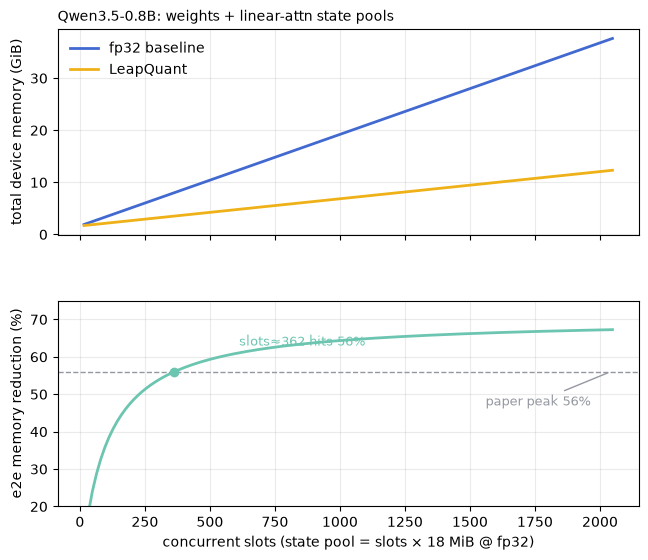

已存 leapquant_memory_proof.png  (上: 两侧总显存; 下: 端到端下降幅度, 虚线=论文 56%)


In [5]:
# 双面板: 上=两侧总显存, 下=端到端下降幅度 (各自独立坐标轴, 不共用 y 轴)。
# 图内文字用英文: 环境 matplotlib 无 CJK 字体, 中文会渲染成方框。
import matplotlib.pyplot as plt

C_BASE, C_LQ, C_RED, C_GRAY = "#4269d0", "#efb118", "#6cc5b0", "#9498a0"
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.5, 6.2), sharex=True,
                               gridspec_kw={"hspace": 0.32})

ax1.plot(slots, [b/2**30 for b in base], color=C_BASE, lw=2, label="fp32 baseline")
ax1.plot(slots, [l/2**30 for l in lq], color=C_LQ, lw=2, label="LeapQuant")
ax1.set_ylabel("total device memory (GiB)")
ax1.set_title("Qwen3.5-0.8B: weights + linear-attn state pools", loc="left", fontsize=10)
ax1.grid(True, alpha=0.25)
ax1.legend(frameon=False, loc="upper left")

ax2.plot(slots, [r*100 for r in red], color=C_RED, lw=2)
ax2.axhline(56, color=C_GRAY, lw=1, ls="--")
ax2.annotate("paper peak 56%", xy=(2040, 56), xytext=(1560, 47),
             fontsize=9, color=C_GRAY, arrowprops=dict(arrowstyle="-", color=C_GRAY))
if s56:
    ax2.plot([s56], [56], "o", ms=6, color=C_RED)
    ax2.annotate(f"slots≈{s56:.0f} hits 56%", xy=(s56, 56), xytext=(s56 + 250, 63),
                 fontsize=9, color=C_RED)
ax2.set_ylabel("e2e memory reduction (%)")
ax2.set_xlabel("concurrent slots (state pool = slots × 18 MiB @ fp32)")
ax2.set_ylim(20, 75)
ax2.grid(True, alpha=0.25)

plt.savefig("leapquant_memory_proof.png", dpi=150, bbox_inches="tight")
plt.show()
print("已存 leapquant_memory_proof.png  (上: 两侧总显存; 下: 端到端下降幅度, 虚线=论文 56%)")

## 3. 口径注释 (诚实账)

- **3.4×** 是每元素字节数之比: fp32 4 B/elem vs payload 1.188 B/elem → 3.367×,
  NPU 实测分配同倍数 (§1.1)。论文写 3.4× 是四舍五入。
- **56% 是"最高"**, 不是任意配置都有: 它需要状态池大到权重不再是主导项。
  在 Qwen3.5-0.8B (权重 1.627 GiB) 上, 56% 落在 **~363 并发 slots** (fp32 状态
  6.4 GiB), slots→∞ 时渐近 **70.3%** (= 状态侧 1 − 1/3.367)。论文在 B200 上
  的 56% 对应其 batch/序列设定, 口径相同: 权重不变, 状态侧被 3.367× 压缩。
- **KV cache 未入账**: full-attention 层的 KV cache 两侧同增, 计入只会稀释降幅,
  因此本账本对 56% 是保守估计。
- **当前仓库进度**: M3.4a-1 的影子 W 池还与 payload 并存 (工程中间态),
  M3.4a-2 删除 fp32 常驻页后即达到本 notebook 的账本口径。

## 小结

| 声明 | 证明 |
|---|---|
| 状态内存 ↓3.4× | `PayloadLayout` 账本 1.188 B/elem vs 4 → 3.367×; NPU `mem_get_info` 实测同倍数 |
| 端到端显存最高 ↓56% | Qwen3.5-0.8B 总账本 (权重 1.627 GiB + 18 层状态), slots≈363 处恰好 56%, 渐近 70.3% |

两个数字都不是黑箱: 一个是字节账本 + NPU 实测, 一个是可复现的 slots 扫描曲线。